# Beginner findings 23-28: exoplanets

Section F was not explored step by step in its own notebook, so the numbers each finding needs are computed here
straight from the planet file (and the Gaia star file for the join) and saved to `numbers/BF23...csv` to
`numbers/BF28...csv`, with a chart for each finding. `gaia_source_id` is read as text.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import helpers as hp
import simple_charts as kc
from bf_tools import Facts, Meet, n0, d, p, g

hp.chart_style()
pl = hp.read_csv("planets")
N = len(pl)
meth = pl["discoverymethod"].where(pl["discoverymethod"].isin(["Transit", "Radial Velocity"]), "Other")
print(f"{N:,} planets; methods: {pl['discoverymethod'].value_counts().to_dict()}")

6,451 planets; methods: {'Transit': 4785, 'Radial Velocity': 1204, 'Microlensing': 292, 'Imaging': 98, 'Transit Timing Variations': 29, 'Eclipse Timing Variations': 17, 'Orbital Brightness Modulation': 9, 'Pulsar Timing': 8, 'Astrometry': 6, 'Pulsation Timing Variations': 2, 'Disk Kinematics': 1}


## Finding 23: planet discoveries arrive in batches

             key  value  shown unit        source
0           rows   6451  6,451           our data
1    transit_all   4785  4,785           our data
2        tr_2014    810    810           our data
3        tr_2016   1432  1,432           our data
4        tr_2015     99     99           our data
5        tr_2013     79     79           our data
6       tot_2025    246    246           our data
7       tot_2026    361    361           our data
8    kepler_2016   1276  1,276           our data
9    kepler_2014    784    784           our data
10    first_year   1992   1992           our data
11  busiest_year   2016   2016           our data
12     busiest_n   1504  1,504           our data
13        y_2013   2013   2013       rule we used
14        y_2014   2014   2014       rule we used
15        y_2015   2015   2015       rule we used
16        y_2016   2016   2016       rule we used
17        y_2025   2025   2025       rule we used
18        y_2026   2026   2026       rule we used


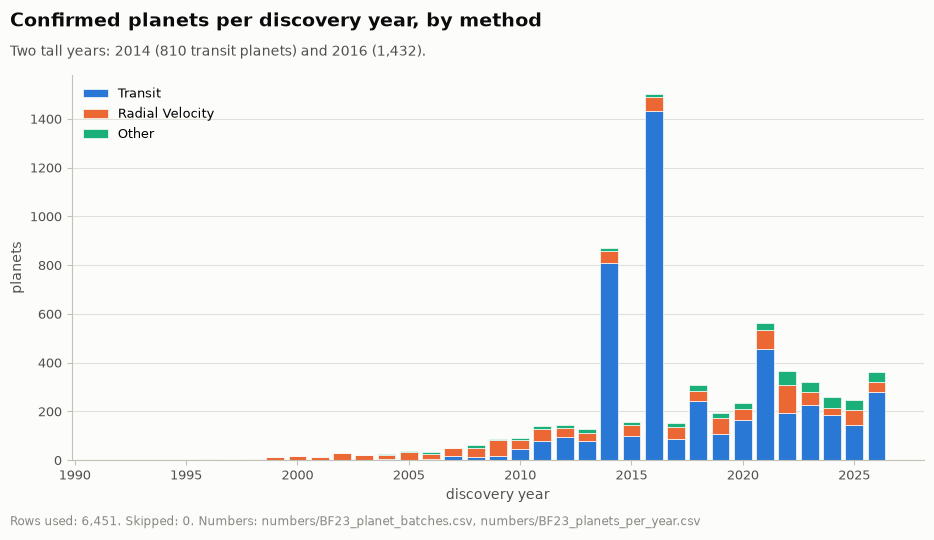

In [2]:
F = Facts(23, "planet_batches")
tab = pd.crosstab(pl["disc_year"].astype(int), meth).reindex(columns=["Transit", "Radial Velocity", "Other"], fill_value=0)
tot = tab.sum(axis=1)
F.add("rows", N); F.add("transit_all", int((pl["discoverymethod"] == "Transit").sum()))
F.add("tr_2014", int(tab.loc[2014, "Transit"])); F.add("tr_2016", int(tab.loc[2016, "Transit"]))
F.add("tr_2015", int(tab.loc[2015, "Transit"])); F.add("tr_2013", int(tab.loc[2013, "Transit"]))
F.add("tot_2025", int(tot[2025])); F.add("tot_2026", int(tot[2026]))
F.add("kepler_2016", int(((pl["disc_facility"] == "Kepler") & (pl["disc_year"] == 2016)).sum()))
F.add("kepler_2014", int(((pl["disc_facility"] == "Kepler") & (pl["disc_year"] == 2014)).sum()))
F.add("first_year", int(pl["disc_year"].min()), str(int(pl["disc_year"].min()))); F.add("busiest_year", int(tot.idxmax()), str(int(tot.idxmax())))
F.add("busiest_n", int(tot.max()))
for y_ in (2013, 2014, 2015, 2016, 2025, 2026):
    F.rule(f"y_{y_}", y_, str(y_))
print(F.table().to_string()); f23 = F.save()
tab.rename_axis("disc_year").reset_index().to_csv(hp.NUMBERS / "BF23_planets_per_year.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(tab))
for col, c in zip(tab.columns, hp.SERIES[:3]):
    ax.bar(tab.index, tab[col], bottom=bottom, color=c, width=0.8, edgecolor=hp.SURFACE, linewidth=0.5, label=col)
    bottom += tab[col].to_numpy()
ax.legend(loc="upper left"); ax.set_xlabel("discovery year"); ax.set_ylabel("planets"); ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Confirmed planets per discovery year, by method",
              f"Two tall years: 2014 ({tab.loc[2014, 'Transit']:,} transit planets) and 2016 ({tab.loc[2016, 'Transit']:,}).",
              hp.caption(N, 0, numbers_file="numbers/BF23_planet_batches.csv, numbers/BF23_planets_per_year.csv"))
c23 = hp.save_chart(fig, "BF23_planets_per_year"); plt.show()
hp.log_entry("F-BF23", "Beginner finding 23 chart: planets per year by method", step=6, chart=c23, numbers=[f23, "numbers/BF23_planets_per_year.csv"],
             rows_used=N, rows_skipped=0, key_numbers=[f"transit 2014 {tab.loc[2014, 'Transit']}, 2016 {tab.loc[2016, 'Transit']}; total 2025 {tot[2025]}, 2026 {tot[2026]}"],
             what_it_shows="Two years stand far above the rest, both made of transit planets.")

## Finding 24: hot Jupiters are common in the list; hot Neptunes are rare

               key        value        shown         unit                            source
0           nep_lo     2.500000          2.5  Earth radii                      rule we used
1           nep_hi     6.000000            6  Earth radii                      rule we used
2               p1     3.000000            3         days                      rule we used
3               p2    10.000000           10         days                      rule we used
4             rows  6050.000000        6,050                                       our data
5       nep_at_2_5    23.000000           23                                       our data
6          nep_lt3    70.000000           70                                       our data
7         nep_3_10   449.000000          449                                       our data
8        nep_ratio     6.414286          6.4                                       our data
9        jup6_lt10   815.000000          815                                    

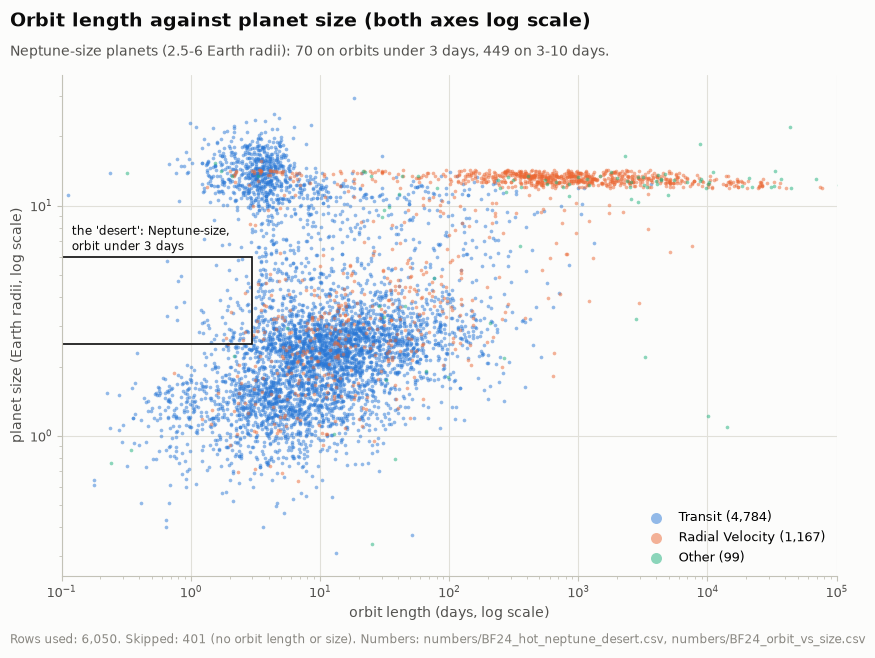

In [3]:
F = Facts(24, "hot_neptune_desert")
ok = pl["pl_orbper"].notna() & pl["pl_rade"].notna()
nep = ok & (pl["pl_rade"] > 2.5) & (pl["pl_rade"] <= 6)  # the guide's edges: more than 2.5, up to 6
F.rule("nep_lo", 2.5, "2.5", "Earth radii"); F.rule("nep_hi", 6, "6", "Earth radii"); F.rule("p1", 3, "3", "days"); F.rule("p2", 10, "10", "days")
F.add("rows", int(ok.sum()))
F.add("nep_at_2_5", int((ok & (pl["pl_rade"] == 2.5)).sum()))
F.add("nep_lt3", int((nep & (pl["pl_orbper"] < 3)).sum())); F.add("nep_3_10", int((nep & (pl["pl_orbper"] >= 3) & (pl["pl_orbper"] < 10)).sum()))
F.add("nep_ratio", (nep & (pl["pl_orbper"] >= 3) & (pl["pl_orbper"] < 10)).sum() / (nep & (pl["pl_orbper"] < 3)).sum(),
      d((nep & (pl["pl_orbper"] >= 3) & (pl["pl_orbper"] < 10)).sum() / (nep & (pl["pl_orbper"] < 3)).sum(), 1))
for lab, lo in [("jup6", 6), ("jup8", 8)]:
    F.add(f"{lab}_lt10", int((ok & (pl["pl_rade"] > lo) & (pl["pl_orbper"] < 10)).sum()))
F.outside("guide_jup", 764, "764", source="Field Guide")
rvflat = ok & (pl["discoverymethod"] == "Radial Velocity") & (pl["pl_rade"] >= 12) & (pl["pl_rade"] <= 13.5)
F.add("rv_flat", int(rvflat.sum())); F.add("rv_with_radius", int((ok & (pl["discoverymethod"] == "Radial Velocity")).sum()))
F.outside("jupiter_re", 11.2, "11.2", "Earth radii", source="known science (Jupiter's radius)")
F.outside("neptune_re", 3.9, "3.9", "Earth radii", source="known science (Neptune's radius)")
hj = pl[pl["pl_name"] == "HD 209458 b"].iloc[0]
F.add("ex_name", 0, hj["pl_name"], source="our data (name)"); F.add("ex_orbper", hj["pl_orbper"], d(hj["pl_orbper"], 2), "days"); F.add("ex_rade", hj["pl_rade"], d(hj["pl_rade"], 1), "Earth radii")
F.rule("jup_size", 8, "8", "Earth radii"); F.rule("flat_lo", 12, "12", "Earth radii"); F.rule("flat_hi", 13.5, "13.5", "Earth radii")
F.rule("zoom_days", 20, "20", "days"); F.rule("zoom_size", 20, "20", "Earth radii")
print(F.table().to_string()); f24 = F.save()
pl.loc[ok, ["pl_name", "pl_orbper", "pl_rade", "discoverymethod"]].to_csv(hp.NUMBERS / "BF24_orbit_vs_size.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 6.5))
for mname, c in zip(["Transit", "Radial Velocity", "Other"], hp.SERIES[:3]):
    q_ = pl[ok & (meth == mname)]
    ax.scatter(q_["pl_orbper"], q_["pl_rade"], s=7, alpha=0.5, color=c, linewidths=0, label=f"{mname} ({len(q_):,})")
ax.add_patch(plt.Rectangle((0.1, 2.5), 3 - 0.1, 3.5, fill=False, color=hp.INK, lw=1.2))
ax.text(0.12, 6.4, "the 'desert': Neptune-size,\norbit under 3 days", fontsize=8.5, color=hp.INK)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.1, 1e5)
ax.set_xlabel("orbit length (days, log scale)"); ax.set_ylabel("planet size (Earth radii, log scale)"); ax.legend(loc="lower right", markerscale=3)
hp.add_titles(fig, "Orbit length against planet size (both axes log scale)",
              f"Neptune-size planets (2.5-6 Earth radii): {int((nep & (pl['pl_orbper'] < 3)).sum())} on orbits under 3 days, "
              f"{int((nep & (pl['pl_orbper'] >= 3) & (pl['pl_orbper'] < 10)).sum())} on 3-10 days.",
              hp.caption(int(ok.sum()), N - int(ok.sum()), "no orbit length or size", "numbers/BF24_hot_neptune_desert.csv, numbers/BF24_orbit_vs_size.csv"))
c24 = hp.save_chart(fig, "BF24_orbit_vs_size"); plt.show()
hp.log_entry("F-BF24", "Beginner finding 24 chart: orbit length against planet size", step=6, chart=c24, numbers=[f24, "numbers/BF24_orbit_vs_size.csv"],
             rows_used=int(ok.sum()), rows_skipped=f"{N - int(ok.sum()):,}", key_numbers=[f"Neptune-size: <3 d {int((nep & (pl['pl_orbper'] < 3)).sum())}, 3-10 d {int((nep & (pl['pl_orbper'] >= 3) & (pl['pl_orbper'] < 10)).sum())}"],
             what_it_shows="Few Neptune-size planets have orbits shorter than 3 days.")

## Finding 25: a gap between rocky and gassy planets

          key        value  shown         unit        source
0        rows  3982.000000  3,982                   our data
1        bins    30.000000     30               rule we used
2       p_cut   100.000000    100         days  rule we used
3      b15_lo     1.467625   1.47                   our data
4      b15_hi     1.594366   1.59                   our data
5       b15_n   233.000000    233                   our data
6      b18_lo     1.732051   1.73                   our data
7      b18_hi     1.881626   1.88                   our data
8       b18_n   199.000000    199                   our data
9      b23_lo     2.220643   2.22                   our data
10     b23_hi     2.412412   2.41                   our data
11      b23_n   347.000000    347                   our data
12   peak1_lo     1.467625   1.47                   our data
13   peak1_hi     1.594366   1.59                   our data
14    peak1_n   233.000000    233                   our data
15   peak2_lo     2.2206

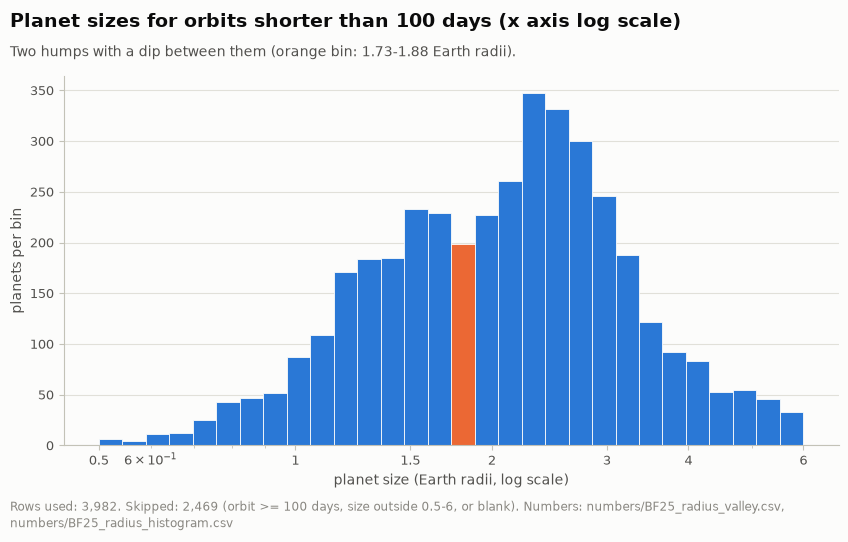

In [4]:
F = Facts(25, "radius_valley")
m25 = ok & (pl["pl_orbper"] < 100) & (pl["pl_rade"] >= 0.5) & (pl["pl_rade"] <= 6)
edges = np.geomspace(0.5, 6, 31)
cnt, _ = np.histogram(pl.loc[m25, "pl_rade"], bins=edges)
F.add("rows", int(m25.sum())); F.rule("bins", 30, "30"); F.rule("p_cut", 100, "100", "days")
def bin_of(x):
    k_ = int(np.searchsorted(edges, x, side="right") - 1)
    return k_
for lab, x in [("b15", 1.5), ("b18", 1.8), ("b23", 2.3)]:
    k_ = bin_of(x)
    F.add(f"{lab}_lo", edges[k_], d(edges[k_], 2)); F.add(f"{lab}_hi", edges[k_ + 1], d(edges[k_ + 1], 2)); F.add(f"{lab}_n", int(cnt[k_]))
small_peak = int(np.argmax(np.where((edges[:-1] >= 1.1) & (edges[:-1] < 1.7), cnt, -1)))
big_peak = int(np.argmax(np.where((edges[:-1] >= 1.9) & (edges[:-1] < 3.2), cnt, -1)))
valley = small_peak + int(np.argmin(cnt[small_peak:big_peak + 1]))
for lab, k_ in [("peak1", small_peak), ("peak2", big_peak), ("valley", valley)]:
    F.add(f"{lab}_lo", edges[k_], d(edges[k_], 2)); F.add(f"{lab}_hi", edges[k_ + 1], d(edges[k_ + 1], 2)); F.add(f"{lab}_n", int(cnt[k_]))
F.rule("size_lo", 0.5, "0.5", "Earth radii"); F.rule("size_hi", 6, "6", "Earth radii")
print(F.table().to_string()); f25 = F.save()
pd.DataFrame({"radius_from": edges[:-1], "radius_to": edges[1:], "planets": cnt}).to_csv(hp.NUMBERS / "BF25_radius_histogram.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(edges[:-1], cnt, width=np.diff(edges), align="edge", color=[hp.SERIES[1] if k_ == valley else hp.SERIES[0] for k_ in range(len(cnt))],
       edgecolor=hp.SURFACE, linewidth=0.6)
ax.set_xscale("log"); ax.set_xticks([0.5, 1, 1.5, 2, 3, 4, 6], ["0.5", "1", "1.5", "2", "3", "4", "6"])
ax.set_xlabel("planet size (Earth radii, log scale)"); ax.set_ylabel("planets per bin"); ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Planet sizes for orbits shorter than 100 days (x axis log scale)",
              f"Two humps with a dip between them (orange bin: {edges[valley]:.2f}-{edges[valley + 1]:.2f} Earth radii).",
              hp.caption(int(m25.sum()), N - int(m25.sum()), "orbit >= 100 days, size outside 0.5-6, or blank", "numbers/BF25_radius_valley.csv, numbers/BF25_radius_histogram.csv"))
c25 = hp.save_chart(fig, "BF25_radius_valley"); plt.show()
hp.log_entry("F-BF25", "Beginner finding 25 chart: planet size histogram (orbits < 100 days)", step=6, chart=c25, numbers=[f25, "numbers/BF25_radius_histogram.csv"],
             rows_used=int(m25.sum()), rows_skipped=f"{N - int(m25.sum()):,}", key_numbers=[f"peaks {edges[small_peak]:.2f} and {edges[big_peak]:.2f}; dip {edges[valley]:.2f}"],
             what_it_shows="Sizes pile up in two humps with a shallow dip between them.")

## Finding 26: planet hunters mostly look at Sun-like stars

                  key         value      shown unit       source
0     matched_planets  2.045000e+03      2,045          our data
1       matched_hosts  1.424000e+03      1,424          our data
2          ids_filled  6.053000e+03      6,053          our data
3   float_changed_pct  5.655047e+01        57%          our data
4          float_join  7.890000e+02        789          our data
5             host_OB  2.808989e-01         0%          our data
6             gaia_OB  5.008205e-01         1%          our data
7              host_A  7.724719e-01         1%          our data
8              gaia_A  1.032056e+00         1%          our data
9              host_F  1.074438e+01        11%          our data
10             gaia_F  4.513575e+00         5%          our data
11             host_G  2.808989e+01        28%          our data
12             gaia_G  5.600271e+00         6%          our data
13             host_K  3.335674e+01        33%          our data
14             gaia_K  1.

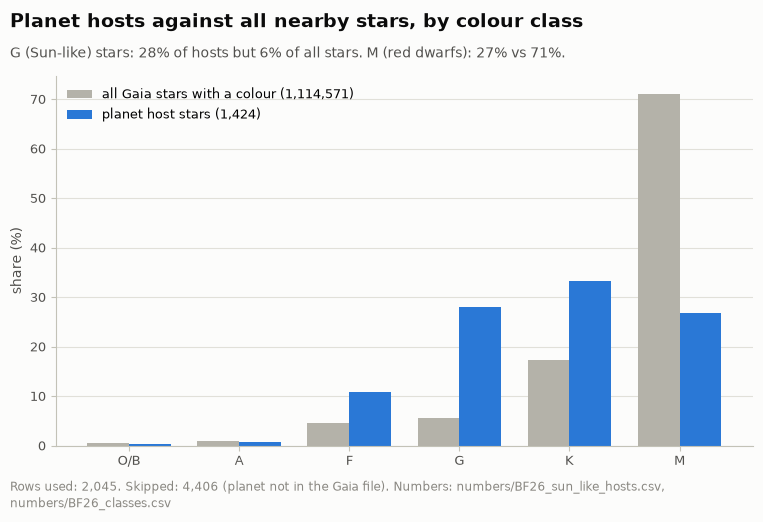

In [5]:
F = Facts(26, "sun_like_hosts")
stars = hp.read_csv("stars", usecols=["source_id", "bp_rp", "abs_g_mag"], dtype_override={"source_id": "str"})
j = pl.merge(stars, left_on="gaia_source_id", right_on="source_id", how="inner")
F.add("matched_planets", len(j)); F.add("matched_hosts", j["gaia_source_id"].nunique()); F.add("ids_filled", int(pl["gaia_source_id"].notna().sum()))
as_float = pd.to_numeric(pl["gaia_source_id"], errors="coerce")
changed = (as_float.dropna().astype("int64").astype(str) != pl["gaia_source_id"].dropna())
F.add("float_changed_pct", 100 * changed.mean(), p(100 * changed.mean()))
sid_int = stars["source_id"].astype("int64")
F.add("float_join", int(as_float.dropna().astype("int64").isin(set(sid_int)).sum()))
cuts = [-np.inf, 0, 0.33, 0.75, 0.98, 1.8, np.inf]; names = ["O/B", "A", "F", "G", "K", "M"]
hosts = j.drop_duplicates("gaia_source_id")
hc = pd.cut(hosts["bp_rp"], cuts, labels=names, right=False).value_counts(normalize=True).reindex(names) * 100
gcl = pd.cut(stars["bp_rp"], cuts, labels=names, right=False).value_counts(normalize=True).reindex(names) * 100
for nm in names:
    k_ = nm.replace("/", "")
    F.add(f"host_{k_}", hc[nm], p(hc[nm])); F.add(f"gaia_{k_}", gcl[nm], p(gcl[nm]))
F.add("hosts_with_colour", int(hosts["bp_rp"].notna().sum())); F.add("gaia_with_colour", int(stars["bp_rp"].notna().sum()))
F.outside("guide_changed", 73, "73%", source="Field Guide"); F.outside("guide_float_join", 555, "555", source="Field Guide")
print(F.table().to_string()); f26 = F.save()
pd.DataFrame({"class": names, "pct_of_host_stars": hc.values, "pct_of_all_gaia_stars": gcl.values}).to_csv(hp.NUMBERS / "BF26_classes.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(names)); wd_ = 0.38
ax.bar(x - wd_ / 2, gcl.values, width=wd_, color=hp.GRAY, label=f"all Gaia stars with a colour ({int(stars['bp_rp'].notna().sum()):,})")
ax.bar(x + wd_ / 2, hc.values, width=wd_, color=hp.SERIES[0], label=f"planet host stars ({int(hosts['bp_rp'].notna().sum()):,})")
ax.set_xticks(x, names); ax.set_ylabel("share (%)"); ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Planet hosts against all nearby stars, by colour class",
              f"G (Sun-like) stars: {hc['G']:.0f}% of hosts but {gcl['G']:.0f}% of all stars. M (red dwarfs): {hc['M']:.0f}% vs {gcl['M']:.0f}%.",
              hp.caption(len(j), N - len(j), "planet not in the Gaia file", "numbers/BF26_sun_like_hosts.csv, numbers/BF26_classes.csv"))
c26 = hp.save_chart(fig, "BF26_host_classes"); plt.show()
hp.log_entry("F-BF26", "Beginner finding 26 chart: host star colour classes against all Gaia stars", step=6, chart=c26, numbers=[f26, "numbers/BF26_classes.csv"],
             rows_used=f"{len(j):,} planets ({j['gaia_source_id'].nunique():,} stars)", rows_skipped=f"{N - len(j):,} planets not in the Gaia file",
             key_numbers=[f"text join {len(j):,} planets; float join {int(as_float.dropna().astype('int64').isin(set(sid_int)).sum()):,}"],
             what_it_shows="Host stars are mostly G and K stars, while most nearby stars are M dwarfs.")

## Finding 27: metal-rich stars host more giant planets

          key        value  shown          unit        source
0    mass_cut    95.000000     95  Earth masses  rule we used
1    size_cut     6.000000      6   Earth radii  rule we used
2       b1_lo    -1.000000   -1.0                rule we used
3       b1_hi    -0.200000   -0.2                rule we used
4        b1_n   689.000000    689                    our data
5   b1_giants   196.000000    196                    our data
6      b1_pct    28.447025    28%                    our data
7       b2_lo    -0.200000   -0.2                rule we used
8       b2_hi     0.000000      0                rule we used
9        b2_n  1905.000000  1,905                    our data
10  b2_giants   441.000000    441                    our data
11     b2_pct    23.149606    23%                    our data
12      b3_lo     0.000000      0                rule we used
13      b3_hi     0.200000    0.2                rule we used
14       b3_n  2311.000000  2,311                    our data
15  b3_g

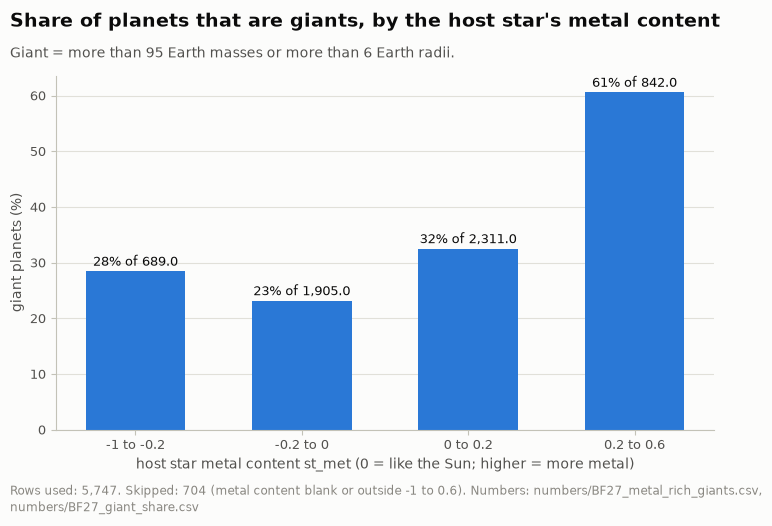

In [6]:
F = Facts(27, "metal_rich_giants")
giant = (pl["pl_bmasse"] > 95) | (pl["pl_rade"] > 6)
F.rule("mass_cut", 95, "95", "Earth masses"); F.rule("size_cut", 6, "6", "Earth radii")
bins = [(-1, -0.2), (-0.2, 0), (0, 0.2), (0.2, 0.6)]
rows = []
for k_, (lo, hi) in enumerate(bins, 1):
    m_ = (pl["st_met"] > lo) & (pl["st_met"] <= hi)  # the guide's edges: more than lo, up to hi
    F.rule(f"b{k_}_lo", lo, d(lo, 1) if lo else "0"); F.rule(f"b{k_}_hi", hi, d(hi, 1) if hi else "0")
    F.add(f"b{k_}_n", int(m_.sum())); F.add(f"b{k_}_giants", int((m_ & giant).sum()))
    F.add(f"b{k_}_pct", 100 * (m_ & giant).sum() / m_.sum(), p(100 * (m_ & giant).sum() / m_.sum()))
    rows.append({"st_met_from": lo, "st_met_to": hi, "planets": int(m_.sum()), "giants": int((m_ & giant).sum()), "pct_giants": 100 * (m_ & giant).sum() / m_.sum()})
F.add("met_blank", int(pl["st_met"].isna().sum()))
F.add("met_rows", sum(r["planets"] for r in rows)); F.add("b3_pct1", rows[2]["pct_giants"], p(rows[2]["pct_giants"], 1))
F.outside("guide_b3", 33, "33%", source="Field Guide")
print(F.table().to_string()); f27 = F.save()
t27 = pd.DataFrame(rows); t27.to_csv(hp.NUMBERS / "BF27_giant_share.csv", index=False)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
labs = [f"{lo} to {hi}" for lo, hi in bins]
ax.bar(labs, t27["pct_giants"], color=hp.SERIES[0], width=0.6)
for k_, r in t27.iterrows():
    ax.text(k_, r["pct_giants"] + 1, f"{r['pct_giants']:.0f}% of {r['planets']:,}", ha="center", fontsize=9, color=hp.INK)
ax.set_xlabel("host star metal content st_met (0 = like the Sun; higher = more metal)"); ax.set_ylabel("giant planets (%)"); ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Share of planets that are giants, by the host star's metal content",
              "Giant = more than 95 Earth masses or more than 6 Earth radii.",
              hp.caption(int(t27["planets"].sum()), N - int(t27["planets"].sum()), "metal content blank or outside -1 to 0.6", "numbers/BF27_metal_rich_giants.csv, numbers/BF27_giant_share.csv"))
c27 = hp.save_chart(fig, "BF27_giant_share"); plt.show()
hp.log_entry("F-BF27", "Beginner finding 27 chart: giant share by metal bin", step=6, chart=c27, numbers=[f27, "numbers/BF27_giant_share.csv"],
             rows_used=int(t27["planets"].sum()), rows_skipped=f"{N - int(t27['planets'].sum()):,}", key_numbers=[" / ".join(f"{v:.0f}%" for v in t27["pct_giants"])],
             what_it_shows="The share of giant planets is highest for the most metal-rich stars.")

## Finding 28: Earth-size planets in the "just right" zone

              key         value          shown         unit                             source
0        size_cut  1.800000e+00            1.8  Earth radii                       rule we used
1        insol_lo  2.500000e-01           0.25                                    rule we used
2        insol_hi  1.500000e+00            1.5                                    rule we used
3               n  4.300000e+01             43                                        our data
4            n_rv  1.800000e+01             18                                        our data
5       n_transit  2.400000e+01             24                                        our data
6        top_name  0.000000e+00  Proxima Cen b                                 our data (name)
7          top_pc  1.301190e+00           1.30           pc                           our data
8           pc_ly  3.260000e+00           3.26  light-years                  README (1 parsec)
9          top_ly  4.241879e+00            4.2  li

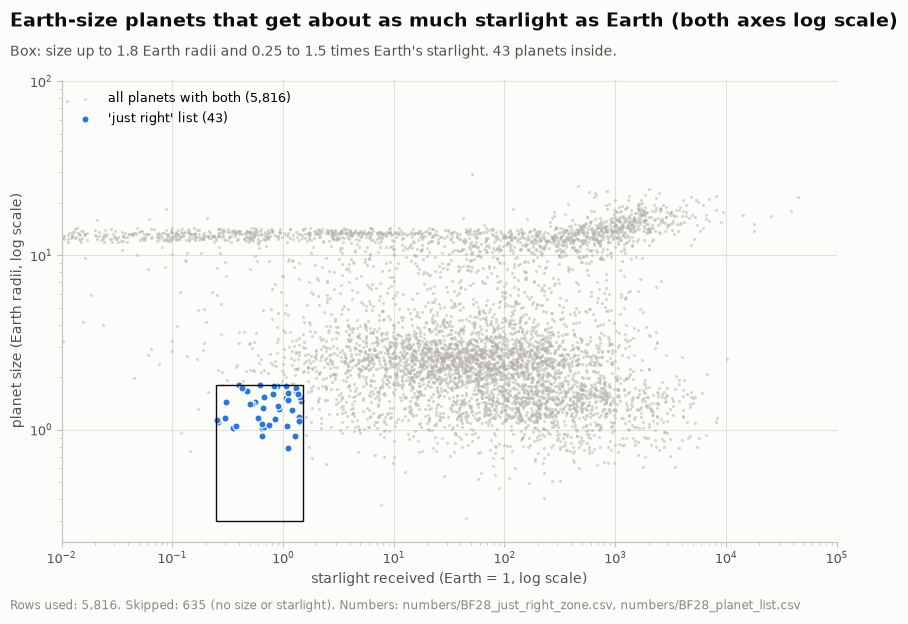

In [7]:
F = Facts(28, "just_right_zone")
jr = pl[(pl["pl_rade"] <= 1.8) & (pl["pl_insol"] >= 0.25) & (pl["pl_insol"] <= 1.5)].sort_values("sy_dist")
F.rule("size_cut", 1.8, "1.8", "Earth radii"); F.rule("insol_lo", 0.25, "0.25"); F.rule("insol_hi", 1.5, "1.5")
F.add("n", len(jr)); F.add("n_rv", int((jr["discoverymethod"] == "Radial Velocity").sum())); F.add("n_transit", int((jr["discoverymethod"] == "Transit").sum()))
top = jr.iloc[0]
F.add("top_name", 0, top["pl_name"], source="our data (name)"); F.add("top_pc", top["sy_dist"], d(top["sy_dist"], 2), "pc")
F.outside("pc_ly", 3.26, "3.26", "light-years", source="README (1 parsec)")
F.add("top_ly", top["sy_dist"] * 3.26, d(top["sy_dist"] * 3.26, 1), "light-years")
F.add("top_rade", top["pl_rade"], d(top["pl_rade"], 2), "Earth radii"); F.add("top_insol", top["pl_insol"], d(top["pl_insol"], 2))
F.outside("voyager_kms", 17, "17", "km/s", source="known science (Voyager 1's speed)")
F.outside("pc_km", 3.0857e13, "30.9 trillion", "km", source="known science (1 parsec)")
yrs = top["sy_dist"] * 3.0857e13 / 17 / (365.25 * 86400)
F.add("voyager_years", yrs, n0(round(yrs, -3)), "years")
F.add("n_within_10pc", int((jr["sy_dist"] < 10).sum()))
F.rule("earth_insol", 1, "1"); F.rule("near_pc", 10, "10", "pc"); F.add("voyager_name", 0, "Voyager 1", source="known name")
print(F.table().to_string()); f28 = F.save()
jr[["pl_name", "sy_dist", "pl_rade", "pl_insol", "discoverymethod", "disc_year"]].to_csv(hp.NUMBERS / "BF28_planet_list.csv", index=False)
okk = pl["pl_rade"].notna() & pl["pl_insol"].notna()
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(pl.loc[okk, "pl_insol"], pl.loc[okk, "pl_rade"], s=5, color=hp.GRAY, alpha=0.5, linewidths=0, label=f"all planets with both ({int(okk.sum()):,})")
ax.scatter(jr["pl_insol"], jr["pl_rade"], s=26, color=hp.SERIES[0], edgecolors=hp.SURFACE, linewidths=0.8, label=f"'just right' list ({len(jr)})")
ax.add_patch(plt.Rectangle((0.25, 0.3), 1.5 - 0.25, 1.8 - 0.3, fill=False, color=hp.INK, lw=1))
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.01, 1e5)
ax.set_xlabel("starlight received (Earth = 1, log scale)"); ax.set_ylabel("planet size (Earth radii, log scale)"); ax.legend(loc="upper left")
hp.add_titles(fig, "Earth-size planets that get about as much starlight as Earth (both axes log scale)",
              f"Box: size up to 1.8 Earth radii and 0.25 to 1.5 times Earth's starlight. {len(jr)} planets inside.",
              hp.caption(int(okk.sum()), N - int(okk.sum()), "no size or starlight", "numbers/BF28_just_right_zone.csv, numbers/BF28_planet_list.csv"))
c28 = hp.save_chart(fig, "BF28_just_right"); plt.show()
hp.log_entry("F-BF28", "Beginner finding 28 chart: just-right planets", step=6, chart=c28, numbers=[f28, "numbers/BF28_planet_list.csv"],
             rows_used=int(okk.sum()), rows_skipped=f"{N - int(okk.sum()):,}", key_numbers=[f"{len(jr)} planets; nearest {top['pl_name']} at {top['sy_dist']:.2f} pc"],
             what_it_shows=f"{len(jr)} planets are Earth-size and get Earth-like starlight; the nearest is {top['pl_name']}.")
hp.edge_case("F", "Full Section F notebook not built (background builders stopped); beginner findings 23-28 were computed in notebooks/BF_F_exoplanets.ipynb.")

## Plain version: "Meet the data" numbers and one plain chart per finding

Numbers for part F's "Meet the data" text: `numbers/BM_F_meet_planets.csv`. New plain charts `charts/K23_...png` to
`charts/K28_...png` (plotted numbers in `numbers/K23_...csv` ...), drawn with `simple_charts`.

In [8]:
kc.plain_style()
M = Meet("F", "meet_planets")
M.add("rows_total", N); M.add("n_columns", len(hp.columns("planets")))
M.add("n_hosts", pl["hostname"].nunique())
M.add("multi_hosts", int((pl.groupby("hostname").size() > 1).sum()))
M.add("first_year", int(pl["disc_year"].min()), str(int(pl["disc_year"].min()))); M.add("last_year", int(pl["disc_year"].max()), str(int(pl["disc_year"].max())))
for col_, key_ in [("pl_rade", "rade"), ("pl_bmasse", "mass"), ("pl_insol", "insol"), ("st_met", "met"), ("pl_orbper", "orbper")]:
    M.add(f"{key_}_blank", int(pl[col_].isna().sum()))
M.add("transit_pct", 100 * (pl["discoverymethod"] == "Transit").mean(), p(100 * (pl["discoverymethod"] == "Transit").mean()))
M.add("rv_pct", 100 * (pl["discoverymethod"] == "Radial Velocity").mean(), p(100 * (pl["discoverymethod"] == "Radial Velocity").mean()))
M.add("n_methods", pl["discoverymethod"].nunique())
ex = pl[pl["pl_name"] == "Proxima Cen b"].iloc[0]
M.add("ex_name", 0, ex["pl_name"], source="our data (name)"); M.add("ex_host", 0, ex["hostname"], source="our data (name)")
M.add("ex_year", int(ex["disc_year"]), str(int(ex["disc_year"]))); M.add("ex_method", 0, ex["discoverymethod"], source="our data (text)")
M.add("ex_facility", 0, ex["disc_facility"], source="our data (text)")
M.add("ex_orbper", ex["pl_orbper"], d(ex["pl_orbper"], 2), "days"); M.add("ex_rade", ex["pl_rade"], d(ex["pl_rade"], 2), "Earth radii")
M.add("ex_mass", ex["pl_bmasse"], d(ex["pl_bmasse"], 2), "Earth masses"); M.add("ex_insol", ex["pl_insol"], d(ex["pl_insol"], 2))
M.add("ex_met", ex["st_met"], d(ex["st_met"], 2) if pd.notna(ex["st_met"]) else "blank", "dex")
M.add("ex_dist", ex["sy_dist"], d(ex["sy_dist"], 2), "pc"); M.add("ex_ly", ex["sy_dist"] * 3.26, d(ex["sy_dist"] * 3.26, 1), "light-years")
M.add("ex_gaia", 0, str(ex["gaia_source_id"]), source="our data (Gaia ID, read as text)")
M.outside("pc_ly", 3.26, "3.26", "light-years", source="README (1 parsec)")
M.outside("earth_year_days", 365.25, "365", "days", source="known science (one Earth year)")
M.add("ex_years_per_earth_year", 365.25 / ex["pl_orbper"], d(365.25 / ex["pl_orbper"], 0), source="our data (365 days ÷ its year)")
print(M.table().to_string()); fmF = M.save()

                        key        value                          shown          unit                            source
0                rows_total  6451.000000                          6,451                                        our data
1                 n_columns    25.000000                             25                                        our data
2                   n_hosts  4847.000000                          4,847                                        our data
3               multi_hosts  1069.000000                          1,069                                        our data
4                first_year  1992.000000                           1992                                        our data
5                 last_year  2026.000000                           2026                                        our data
6                rade_blank    50.000000                             50                                        our data
7                mass_blank    30.000000

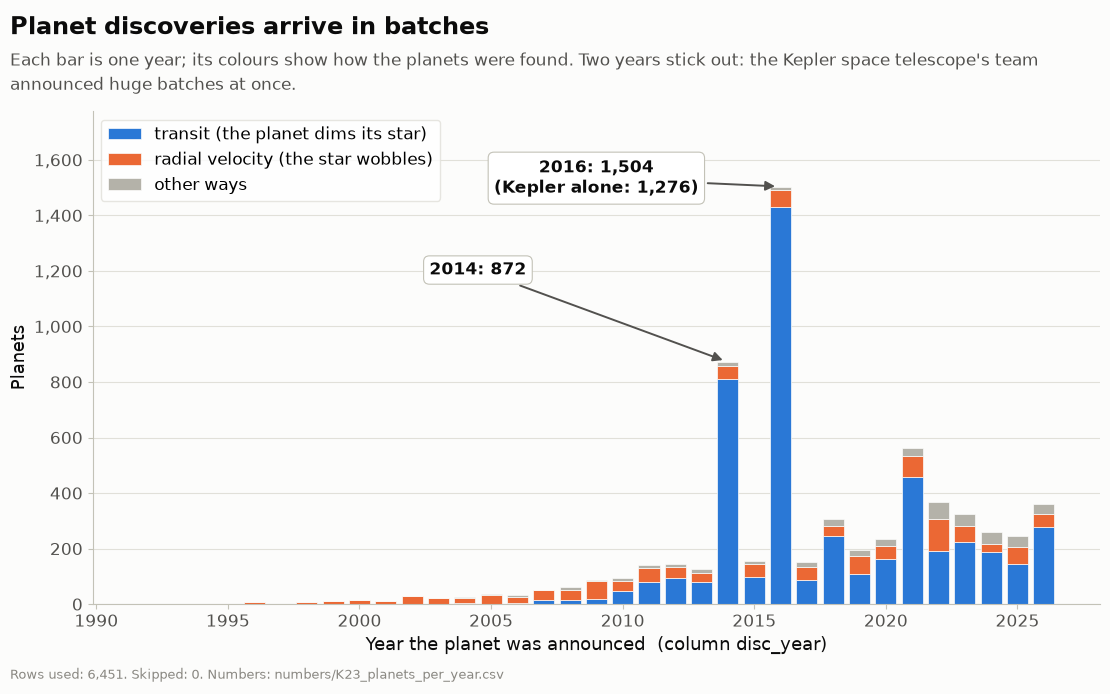

In [9]:
# K23: planets per discovery year, by how they were found
t23 = tab.rename_axis("disc_year").reset_index()
n23 = hp.save_numbers(t23, "K23_planets_per_year")
fig, ax = plt.subplots(figsize=(13, 6.4))
bottom = np.zeros(len(tab))
for col, c, lab in zip(tab.columns, [kc.MAIN, kc.HIGHLIGHT, kc.OTHER],
                       ["transit (the planet dims its star)", "radial velocity (the star wobbles)", "other ways"]):
    ax.bar(tab.index, tab[col], bottom=bottom, color=c, width=0.8, edgecolor=hp.SURFACE, linewidth=0.5, label=lab)
    bottom += tab[col].to_numpy()
kc.point_at(ax, (2014, tot[2014]), f"2014: {n0(tot[2014])}", (2004.5, tot.max() * 0.8))
kc.point_at(ax, (2016, tot[2016]), f"2016: {n0(tot[2016])}\n(Kepler alone: {n0(int(((pl['disc_facility'] == 'Kepler') & (pl['disc_year'] == 2016)).sum()))})",
            (2009, tot.max() * 1.02))
ax.set_ylim(0, tot.max() * 1.18); ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor=hp.GRID)
ax.set_xlabel("Year the planet was announced  (column disc_year)"); ax.set_ylabel("Planets"); kc.plain_axis(ax, "y")
ax.grid(axis="x", visible=False)
kc.titles(fig, "Planet discoveries arrive in batches",
          "Each bar is one year; its colours show how the planets were found. Two years stick out: the Kepler space "
          "telescope's team announced huge batches at once.",
          hp.caption(N, 0, "", n23))
c23_ = kc.save(fig, "K23_planets_per_year"); plt.show()
hp.log_entry("F-K23", "Simple chart for finding 23: planets per year by method", step=6, chart=c23_, numbers=n23, rows_used=N,
             key_numbers=[f"2014 {tot[2014]:,}; 2016 {tot[2016]:,}"], what_it_shows="Two tall batch years, 2014 and 2016, mostly transit planets.")

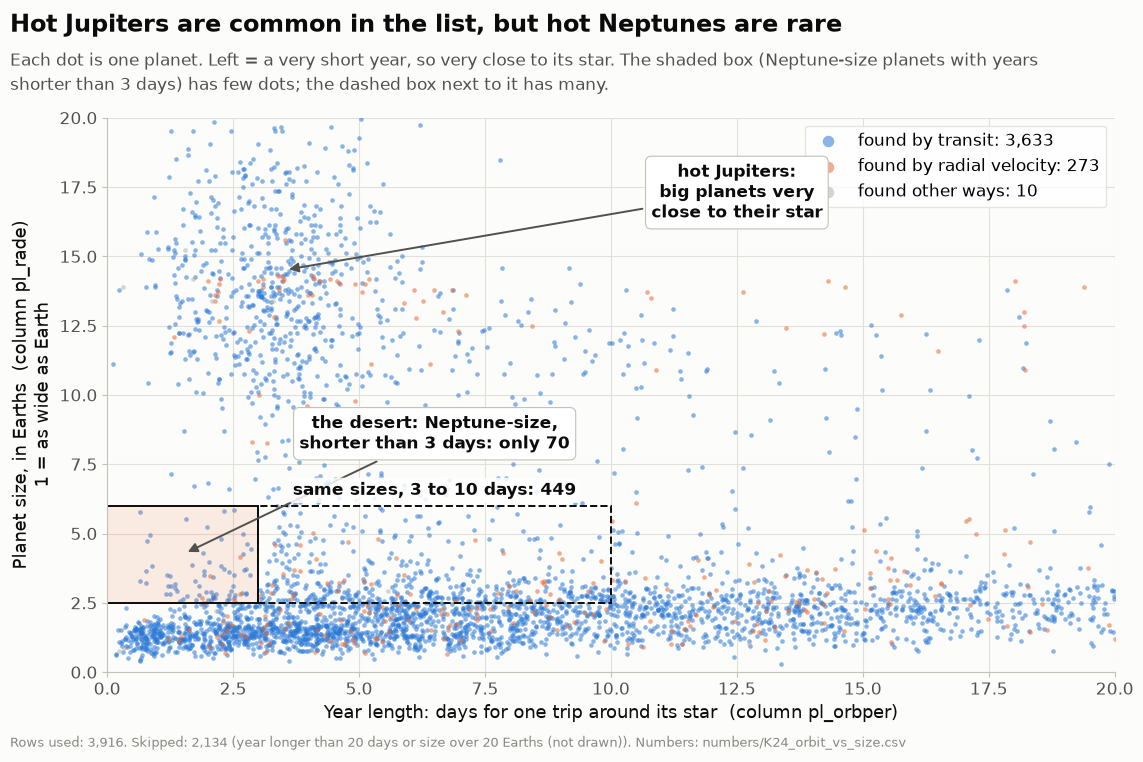

In [10]:
# K24: a zoom on short orbits with plain axes: orbit length (days) against size (Earth sizes)
z24 = ok & (pl["pl_orbper"] <= 20) & (pl["pl_rade"] <= 20)
fig, ax = plt.subplots(figsize=(13, 7.2))
for mname, c, lab in zip(["Transit", "Radial Velocity", "Other"], [kc.MAIN, kc.HIGHLIGHT, kc.OTHER],
                         ["found by transit", "found by radial velocity", "found other ways"]):
    q_ = pl[z24 & (meth == mname)]
    ax.scatter(q_["pl_orbper"], q_["pl_rade"], s=11, alpha=0.55, color=c, linewidths=0, label=f"{lab}: {n0(len(q_))}")
ax.add_patch(plt.Rectangle((0, 2.5), 3, 3.5, color=hp.SERIES[1], alpha=0.12, lw=0))
ax.add_patch(plt.Rectangle((0, 2.5), 3, 3.5, fill=False, color=hp.INK, lw=1.4))
ax.add_patch(plt.Rectangle((3, 2.5), 7, 3.5, fill=False, color=hp.INK, lw=1.4, ls="--"))
kc.point_at(ax, (1.5, 4.25), f"the desert: Neptune-size,\nshorter than 3 days: only {n0((nep & (pl['pl_orbper'] < 3)).sum())}", (6.5, 8.6))
kc.label(ax, 6.5, 6.25, f"same sizes, 3 to 10 days: {n0((nep & (pl['pl_orbper'] >= 3) & (pl['pl_orbper'] < 10)).sum())}", ha="center", va="bottom", bold=True, box=True)
kc.point_at(ax, (3.5, 14.5), "hot Jupiters:\nbig planets very\nclose to their star", (12.5, 17.3))
ax.set_xlim(0, 20); ax.set_ylim(0, 20)
ax.set_xlabel("Year length: days for one trip around its star  (column pl_orbper)")
ax.set_ylabel("Planet size, in Earths  (column pl_rade)\n1 = as wide as Earth")
ax.legend(loc="upper right", markerscale=2.5, frameon=True, facecolor="white", edgecolor=hp.GRID)
n24 = hp.save_numbers(pd.DataFrame({"what": ["Neptune-size, shorter than 3 days", "Neptune-size, 3 to 10 days", "Jupiter-size (over 8), shorter than 10 days",
                                             "planets drawn (orbit up to 20 days, size up to 20)"],
                                    "planets": [int((nep & (pl["pl_orbper"] < 3)).sum()), int((nep & (pl["pl_orbper"] >= 3) & (pl["pl_orbper"] < 10)).sum()),
                                                int((ok & (pl["pl_rade"] > 8) & (pl["pl_orbper"] < 10)).sum()), int(z24.sum())]}), "K24_orbit_vs_size")
kc.titles(fig, "Hot Jupiters are common in the list, but hot Neptunes are rare",
          "Each dot is one planet. Left = a very short year, so very close to its star. The shaded box (Neptune-size planets "
          "with years shorter than 3 days) has few dots; the dashed box next to it has many.",
          hp.caption(int(z24.sum()), int(ok.sum()) - int(z24.sum()), "year longer than 20 days or size over 20 Earths (not drawn)", n24))
c24_ = kc.save(fig, "K24_orbit_vs_size"); plt.show()
hp.log_entry("F-K24", "Simple chart for finding 24: the hot Neptune desert, plain axes", step=6, chart=c24_, numbers=n24,
             rows_used=int(z24.sum()), key_numbers=[f"desert {int((nep & (pl['pl_orbper'] < 3)).sum())} vs {int((nep & (pl['pl_orbper'] >= 3) & (pl['pl_orbper'] < 10)).sum())}"],
             what_it_shows="Neptune-size planets with years under 3 days are rare; hot Jupiters cluster at short years.")

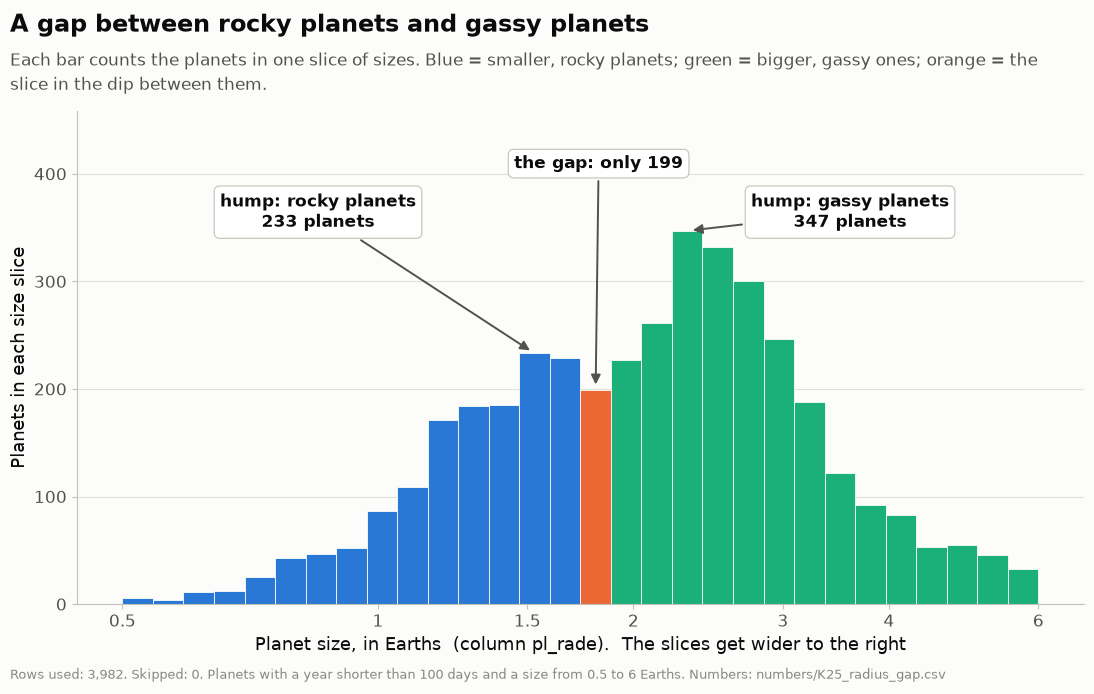

In [11]:
# K25: planet sizes for years shorter than 100 days, with the two humps and the dip marked
n25 = hp.save_numbers(pd.DataFrame({"size_from": edges[:-1].round(3), "size_to": edges[1:].round(3), "planets": cnt}), "K25_radius_gap")
fig, ax = plt.subplots(figsize=(13, 6.4))
col25 = [kc.HIGHLIGHT if k_ == valley else (kc.MAIN if edges[k_] < edges[valley] else hp.SERIES[2]) for k_ in range(len(cnt))]
ax.bar(edges[:-1], cnt, width=np.diff(edges), align="edge", color=col25, edgecolor=hp.SURFACE, linewidth=0.6)
ax.set_xscale("log"); ax.set_xticks([0.5, 1, 1.5, 2, 3, 4, 6], ["0.5", "1", "1.5", "2", "3", "4", "6"]); ax.minorticks_off()
for k_, txt, xy_t in [(small_peak, f"hump: rocky planets\n{n0(cnt[small_peak])} planets", (0.85, cnt.max() * 1.05)),
                      (valley, f"the gap: only {n0(cnt[valley])}", (1.82, cnt.max() * 1.18)),
                      (big_peak, f"hump: gassy planets\n{n0(cnt[big_peak])} planets", (3.6, cnt.max() * 1.05))]:
    kc.point_at(ax, (np.sqrt(edges[k_] * edges[k_ + 1]), cnt[k_]), txt, xy_t)
ax.set_ylim(0, cnt.max() * 1.32)
ax.set_xlabel("Planet size, in Earths  (column pl_rade).  The slices get wider to the right")
ax.set_ylabel("Planets in each size slice"); kc.plain_axis(ax, "y"); ax.grid(axis="x", visible=False)
kc.titles(fig, "A gap between rocky planets and gassy planets",
          "Each bar counts the planets in one slice of sizes. Blue = smaller, rocky planets; green = bigger, gassy ones; "
          "orange = the slice in the dip between them.",
          hp.caption(int(m25.sum()), 0, "", n25, extra="Planets with a year shorter than 100 days and a size from 0.5 to 6 Earths."))
c25_ = kc.save(fig, "K25_radius_gap"); plt.show()
hp.log_entry("F-K25", "Simple chart for finding 25: the radius gap", step=6, chart=c25_, numbers=n25, rows_used=int(m25.sum()),
             key_numbers=[f"humps {cnt[small_peak]} and {cnt[big_peak]}, dip {cnt[valley]}"], what_it_shows="Two humps of planet sizes with a dip between them.")

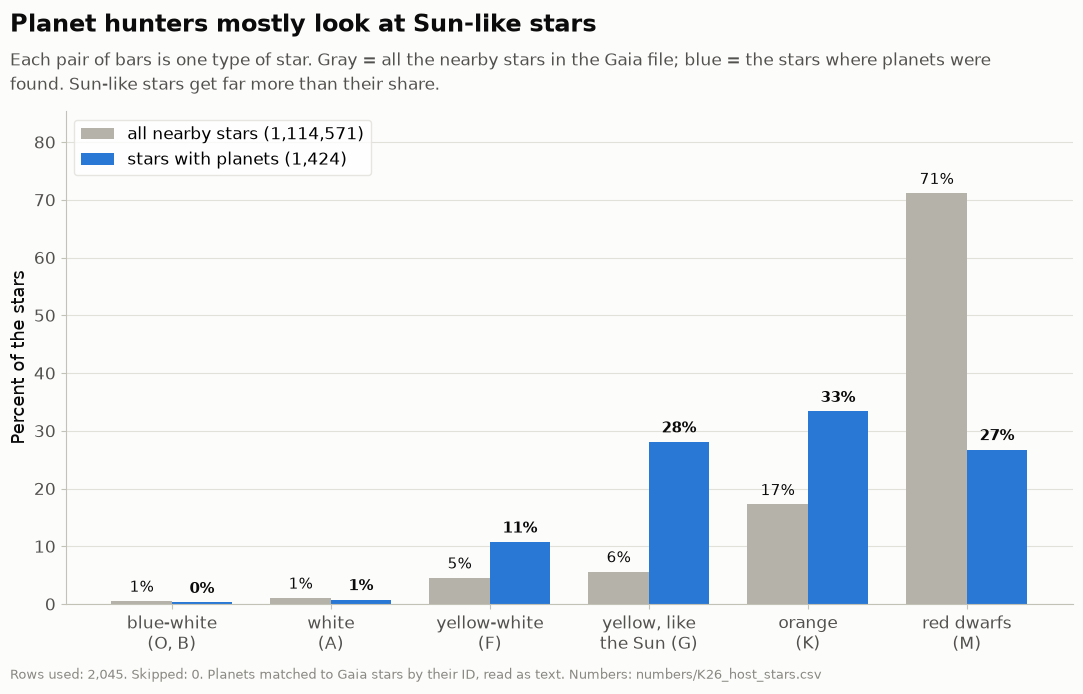

In [12]:
# K26: star types of planet hosts against all nearby stars
KN = {"O/B": "blue-white\n(O, B)", "A": "white\n(A)", "F": "yellow-white\n(F)", "G": "yellow, like\nthe Sun (G)", "K": "orange\n(K)", "M": "red dwarfs\n(M)"}
n26 = hp.save_numbers(pd.DataFrame({"type": names, "pct_all_nearby_stars": gcl.round(1).values, "pct_planet_hosts": hc.round(1).values}), "K26_host_stars")
fig, ax = plt.subplots(figsize=(13, 6.4))
x = np.arange(len(names)); wd_ = 0.38
ax.bar(x - wd_ / 2, gcl.values, width=wd_, color=kc.OTHER, label=f"all nearby stars ({n0(stars['bp_rp'].notna().sum())})")
ax.bar(x + wd_ / 2, hc.values, width=wd_, color=kc.MAIN, label=f"stars with planets ({n0(hosts['bp_rp'].notna().sum())})")
for k_ in range(len(names)):
    kc.label(ax, k_ - wd_ / 2, gcl.values[k_] + 1, p(gcl.values[k_]), ha="center", va="bottom", fontsize=11)
    kc.label(ax, k_ + wd_ / 2, hc.values[k_] + 1, p(hc.values[k_]), ha="center", va="bottom", fontsize=11, bold=True)
ax.set_xticks(x, [KN[nm] for nm in names]); ax.set_ylim(0, max(gcl.max(), hc.max()) * 1.2)
ax.set_ylabel("Percent of the stars"); ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor=hp.GRID); ax.grid(axis="x", visible=False)
kc.titles(fig, "Planet hunters mostly look at Sun-like stars",
          "Each pair of bars is one type of star. Gray = all the nearby stars in the Gaia file; blue = the stars where "
          "planets were found. Sun-like stars get far more than their share.",
          hp.caption(len(j), 0, "", n26, extra="Planets matched to Gaia stars by their ID, read as text."))
c26_ = kc.save(fig, "K26_host_stars"); plt.show()
hp.log_entry("F-K26", "Simple chart for finding 26: host star types against all nearby stars", step=6, chart=c26_, numbers=n26,
             rows_used=len(j), key_numbers=[f"G: hosts {hc['G']:.0f}% vs all {gcl['G']:.0f}%; M: {hc['M']:.0f}% vs {gcl['M']:.0f}%"],
             what_it_shows="Sun-like (G, K) stars are over-represented among planet hosts; red dwarfs are under-represented.")

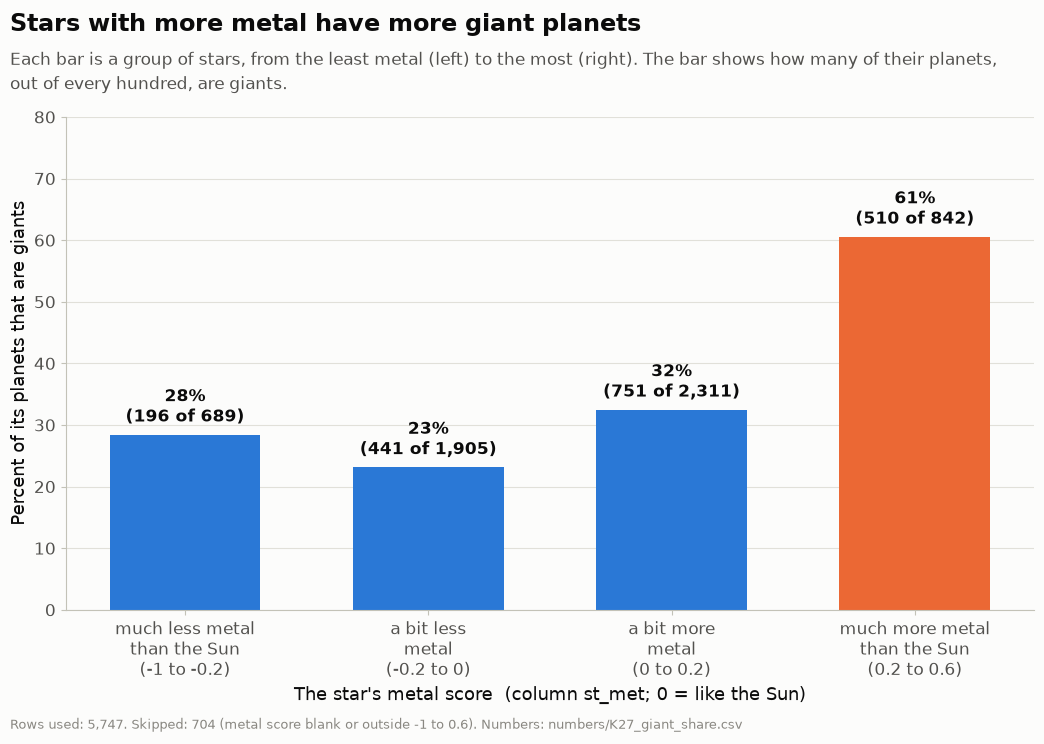

In [13]:
# K27: share of giant planets by the star's metal score
labs27 = ["much less metal\nthan the Sun", "a bit less\nmetal", "a bit more\nmetal", "much more metal\nthan the Sun"]
n27 = hp.save_numbers(t27.assign(label=[l_.replace("\n", " ") for l_ in labs27]), "K27_giant_share")
fig, ax = plt.subplots(figsize=(12.5, 6.4))
ax.bar(range(4), t27["pct_giants"], color=[kc.MAIN, kc.MAIN, kc.MAIN, kc.HIGHLIGHT], width=0.62)
for k_, r in t27.iterrows():
    kc.label(ax, k_, r["pct_giants"] + 1.2, f"{p(r['pct_giants'])}\n({n0(r['giants'])} of {n0(r['planets'])})", ha="center", va="bottom", bold=True)
ax.set_xticks(range(4), [f"{l_}\n({lo:g} to {hi:g})" for l_, (lo, hi) in zip(labs27, bins)]); ax.set_ylim(0, 80)
ax.set_xlabel("The star's metal score  (column st_met; 0 = like the Sun)")
ax.set_ylabel("Percent of its planets that are giants"); ax.grid(axis="x", visible=False)
kc.titles(fig, "Stars with more metal have more giant planets",
          "Each bar is a group of stars, from the least metal (left) to the most (right). The bar shows how many of their "
          "planets, out of every hundred, are giants.",
          hp.caption(int(t27["planets"].sum()), N - int(t27["planets"].sum()), "metal score blank or outside -1 to 0.6", n27))
c27_ = kc.save(fig, "K27_giant_share"); plt.show()
hp.log_entry("F-K27", "Simple chart for finding 27: giant share by metal score", step=6, chart=c27_, numbers=n27,
             rows_used=int(t27["planets"].sum()), key_numbers=[" / ".join(p(v) for v in t27["pct_giants"])],
             what_it_shows="The giant share is highest for the most metal-rich stars.")

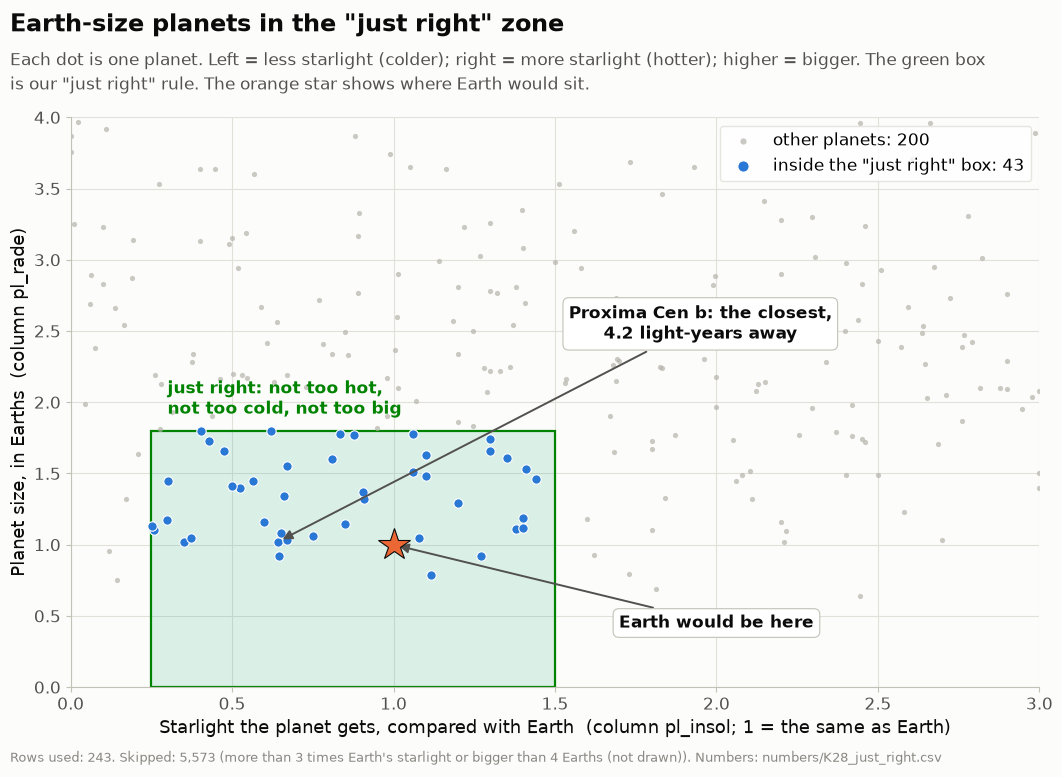

In [14]:
# K28: the "just right" box on plain axes: starlight (Earth = 1) against size (Earth = 1)
z28 = okk & (pl["pl_insol"] <= 3) & (pl["pl_rade"] <= 4)
fig, ax = plt.subplots(figsize=(12.5, 7.4))
ax.add_patch(plt.Rectangle((0.25, 0), 1.25, 1.8, color=hp.SERIES[2], alpha=0.15, lw=0))
ax.add_patch(plt.Rectangle((0.25, 0), 1.25, 1.8, fill=False, color=hp.SERIES[5], lw=1.6))
outside = pl[z28 & ~pl.index.isin(jr.index)]
ax.scatter(outside["pl_insol"], outside["pl_rade"], s=14, color=kc.OTHER, alpha=0.7, linewidths=0, label=f"other planets: {n0(len(outside))}")
ax.scatter(jr["pl_insol"], jr["pl_rade"], s=46, color=kc.MAIN, edgecolors="white", linewidths=0.8, label=f"inside the \"just right\" box: {len(jr)}")
ax.plot([1], [1], marker="*", ms=24, color=kc.HIGHLIGHT, mec=hp.INK, mew=0.8, zorder=11)
kc.point_at(ax, (1, 1), "Earth would be here", (2.0, 0.45))
kc.point_at(ax, (top["pl_insol"], top["pl_rade"]), f"{top['pl_name']}: the closest,\n{d(top['sy_dist'] * 3.26, 1)} light-years away", (1.95, 2.55))
kc.label(ax, 0.3, 1.88, "just right: not too hot,\nnot too cold, not too big", ha="left", va="bottom", color=hp.SERIES[5], bold=True)
ax.set_xlim(0, 3); ax.set_ylim(0, 4)
ax.set_xlabel("Starlight the planet gets, compared with Earth  (column pl_insol; 1 = the same as Earth)")
ax.set_ylabel("Planet size, in Earths  (column pl_rade)")
ax.legend(loc="upper right", markerscale=1.2, frameon=True, facecolor="white", edgecolor=hp.GRID)
n28 = hp.save_numbers(jr[["pl_name", "sy_dist", "pl_rade", "pl_insol", "discoverymethod"]].round(3), "K28_just_right")
kc.titles(fig, "Earth-size planets in the \"just right\" zone",
          "Each dot is one planet. Left = less starlight (colder); right = more starlight (hotter); higher = bigger. "
          "The green box is our \"just right\" rule. The orange star shows where Earth would sit.",
          hp.caption(int(z28.sum()), int(okk.sum()) - int(z28.sum()), "more than 3 times Earth's starlight or bigger than 4 Earths (not drawn)", n28))
c28_ = kc.save(fig, "K28_just_right"); plt.show()
hp.log_entry("F-K28", "Simple chart for finding 28: the just-right box on plain axes", step=6, chart=c28_, numbers=n28, rows_used=int(z28.sum()),
             key_numbers=[f"{len(jr)} planets in the box; nearest {top['pl_name']}"], what_it_shows="A few dozen planets sit in the box near Earth's spot.")